# analysis and plot the EDA OBS dataset 
input: 
- data from nbook 6 

outputs:
- plot with timeseries how many pixels are NAN
- global map with nan counts (per pixel)
- map but per month or so
- histograms missing pixels with and withput 4 bad timestamps



In [1]:
import xarray as xr

# plotting
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import cartopy.crs as ccrs

import numpy as np
import xarray as xr
import seaborn as sns
from datetime import datetime


import os

# import colors for plotting
import sys 
sys.path.append("../tools")
from defs_application import * # color_precip_obs etc


# load data

In [2]:
plotsavedir = "../output/plots/"
os.makedirs(plotsavedir, exist_ok=True)

In [3]:
def summarize_period(data, date_suffixes, month=None, year=None):
    """
    Summarize loaded data over a defined time period.
    
    Parameters
    ----------
    data         : dict of lists, as returned by the loading block
    date_suffixes: list of date suffix strings (same order as data lists)
    month        : int or None — filter to this month (1–12)
    year         : int or None — filter to this year (e.g. 2023)
    
    Returns
    -------
    dict with keys: precip_count, tb_count, iwp_count, precip_map, tb_map, iwp_map
    label        : string describing the period (for plot titles)
    """
    # build boolean mask over date_suffixes
    mask = []
    for d in date_suffixes:
        dt = datetime.strptime(d[:10], "%Y-%m-%d")
        keep = True
        if month is not None and dt.month != month:
            keep = False
        if year is not None and dt.year != year:
            keep = False
        mask.append(keep)

    # apply mask to each data list
    filtered = {name: [ds for ds, m in zip(data[name], mask) if m]
                for name in data}

    # build label
    month_str = datetime(2000, month, 1).strftime("%B") if month else None
    parts = [str(year) if year else None, month_str]
    label = " ".join(p for p in parts if p) or "all"

    ds = {
        "precip_count": xr.concat(filtered["precip_count"], dim="time"),
        "tb_count":     xr.concat(filtered["tb_count"],     dim="time"),
        "iwp_count":    xr.concat(filtered["iwp_count"],    dim="time"),
        "precip_map":   sum(filtered["precip_map"]),
        "tb_map":       sum(filtered["tb_map"]),
        "iwp_map":      sum(filtered["iwp_map"]),
    }
    return ds, label

In [4]:
input_dir = "../output/_output_nogaus_important/EDA_OBS"


name_types = ["precip_count", "tb_count", "iwp_count", "precip_map", "tb_map", "iwp_map"]
file_keys  = ["precip_quality_counts", "tb_quality_counts", "iwp_quality_counts",
              "precip_quality_maps",   "tb_quality_maps",   "iwp_quality_maps"]

# get all date suffixes from the reference file type
date_suffixes = [f.replace("precip_quality_counts_", "").replace(".nc", "")
                 for f in sorted(os.listdir(input_dir))
                 if f.startswith("precip_quality_counts_")]

data = {name: [] for name in name_types}

for date_suffix in date_suffixes:
    for name, key in zip(name_types, file_keys):
        data[name].append(xr.open_dataset(os.path.join(input_dir, f"{key}_{date_suffix}.nc"), engine="h5netcdf"))


# summarize (in one cell bc of annoying output)
date_label_map = "2023"
result, label = summarize_period(data, date_suffixes)

date_label_map_june = "June 2023"
result_june, label_june = summarize_period(data, date_suffixes, month = 6)

date_label_map_december = "December 2023"
result_december, label_december= summarize_period(data, date_suffixes, month = 12)


# Map

In [6]:
def domain_plot_missing(data,totaltimestamps,vmax=None, domain=[-30, 30, -30, 30], left_grid_label=True, bottom_grid_label=True, figsize=(15, 10), title="", fig=None, ax=None):
    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
    import seaborn as sns

    sns.set_context("talk")
    figisselfcreated = False
    if fig is None or ax is None:
        figisselfcreated = True
        fig = plt.figure(figsize=figsize)
        ax = plt.axes(projection=ccrs.PlateCarree())

    lon_min, lon_max, lat_min, lat_max = domain
    data = data.sel(
        longitude=slice(lon_min, lon_max),
        latitude=slice(lat_min, lat_max)
    )
    
    pct_missing = (data / totaltimestamps) * 100
    
    if vmax is None:
        vmax = 100
    cmap = plt.cm.YlOrRd.copy()
    cmap.set_bad("lightgrey")
    cmap.set_under("white")
        
    pcm = ax.pcolormesh(
        pct_missing.longitude, pct_missing.latitude, pct_missing,
        cmap=cmap,
        vmin=0.000001, vmax=vmax,
        transform=ccrs.PlateCarree(),
        shading="auto",
        rasterized=True)

    gl = ax.gridlines(
        crs=ccrs.PlateCarree(), draw_labels=True,
        linewidth=0.6, color='gray', alpha=0.2, linestyle='--'
    )
    gl.top_labels = False
    gl.right_labels = False
    gl.left_labels = left_grid_label
    gl.bottom_labels = bottom_grid_label
    gl.xformatter = LONGITUDE_FORMATTER
    gl.yformatter = LATITUDE_FORMATTER

    ax.set_extent(domain, crs=ccrs.PlateCarree())
    ax.coastlines(color='grey', linewidth=1)
    ax.set_title(title, fontweight="bold")

    if figisselfcreated:
        plt.show()
    return fig, ax, gl

In [7]:
def gettotaltimestampsfrompreciptcount(data):
    days = len(data["precip_count"])
    timestampsperday = len(data["precip_count"][0].time) # is 8 by definition (3 hourly mean)
    totaltimestamps = days*timestampsperday
    return totaltimestamps

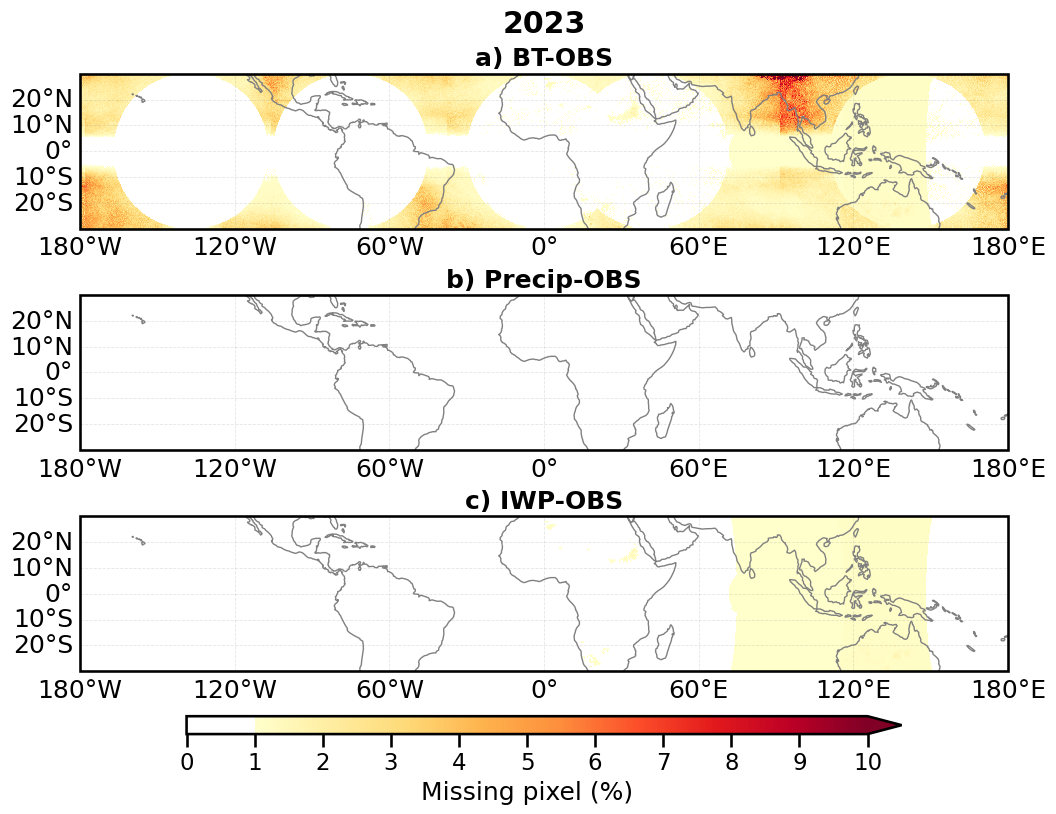

In [8]:
vmax = 10

sns.set_context("talk")
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True
)
totaltimestamps = gettotaltimestampsfrompreciptcount(data)

fig, axes[0], _ = domain_plot_missing(result["tb_map"]["nan"],    totaltimestamps= totaltimestamps, vmax=vmax, domain=[-180,180,-30,30], title="a) BT-OBS",     fig=fig, ax=axes[0])
fig, axes[1], _ = domain_plot_missing(result["precip_map"]["nan"], totaltimestamps= totaltimestamps, vmax=vmax, domain=[-180,180,-30,30], title="b) Precip-OBS", fig=fig, ax=axes[1])
fig, axes[2], _ = domain_plot_missing(result["iwp_map"]["nan"],    totaltimestamps= totaltimestamps, vmax=vmax, domain=[-180,180,-30,30], title="c) IWP-OBS",    fig=fig, ax=axes[2])

# single shared colorbar below all panels
pcm = axes[0].collections[0]
sm = plt.cm.ScalarMappable(cmap=pcm.cmap, norm=plt.Normalize(vmin=1, vmax=vmax))

cbar = fig.colorbar(sm, ax=axes, orientation="horizontal", pad=0.02, shrink=0.6, aspect=40, extend="max")
cbar.set_ticks(range(0, vmax + 1, max(1, vmax // 10)))
cbar.set_label("Missing pixel (%)")

fig.suptitle(f"{date_label_map}", fontweight="bold") #Missing Pixels - Full 
#plt.savefig(os.path.join(plotsavedir,"missingpixels_2023_ts_maps.pdf"),bbox_inches="tight")
plt.show()

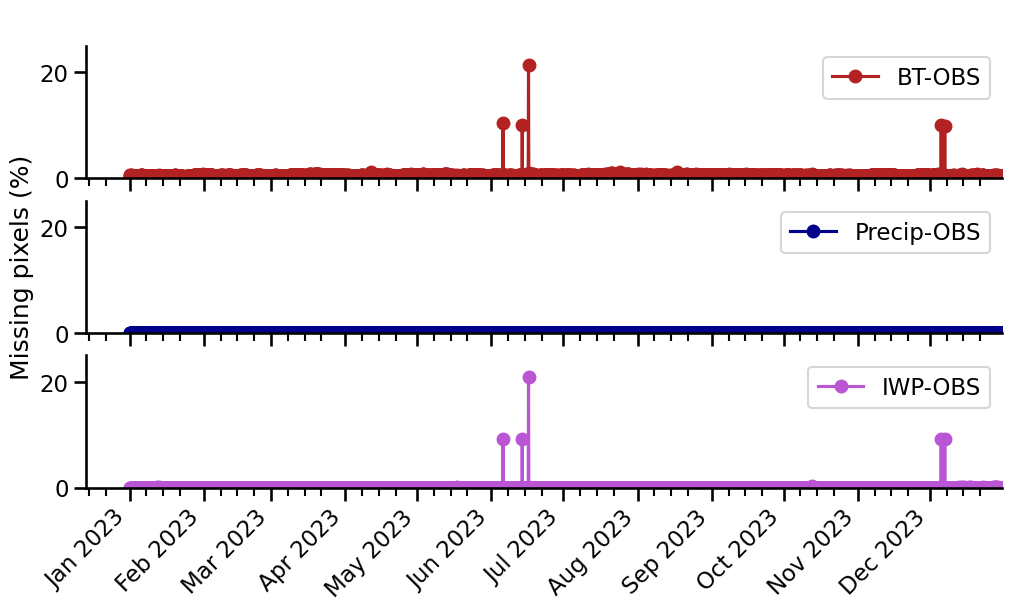

In [9]:
sns.set_context("talk")

# fig set up
fig = plt.figure(figsize=(10, 6), constrained_layout=True)
gs = GridSpec(2, 1, figure=fig, height_ratios=[0.05, 1])

ax_col1_title = fig.add_subplot(gs[0, 0])
#ax_col1_title.text(0.5, 0.5, "Missing pixels per timestamp", ha='center', va='center', fontweight='bold', transform=ax_col1_title.transAxes)
ax_col1_title.axis('off')

ax_ts = gs[1, 0].subgridspec(3, 1, hspace=0.0)
ax_ts1 = fig.add_subplot(ax_ts[0])
ax_ts2 = fig.add_subplot(ax_ts[1], sharex=ax_ts1)
ax_ts3 = fig.add_subplot(ax_ts[2], sharex=ax_ts1)

# timeseries
totalpixels = result["precip_map"]["nan"].size
ax_ts1.plot(result["tb_count"].time, 100 * result["tb_count"]["nan"] / totalpixels, label="BT-OBS", color=color_tb_obs, marker='o', zorder=1)
ax_ts2.plot(result["precip_count"].time, 100 * result["precip_count"]["nan"] / totalpixels, label="Precip-OBS", color=color_precip_obs, marker='o')
ax_ts3.plot(result["iwp_count"].time, 100 * result["iwp_count"]["nan"] / totalpixels, label="IWP-OBS", color=color_iwp_obs, marker='o', zorder=0)

# formatting
for ax in [ax_ts1, ax_ts2, ax_ts3]:
    ax.set_ylim(0, 25)
    ax.legend(frameon=True)
    sns.despine(ax=ax)
ax_ts2.set_ylabel("Missing pixels (%)")

# year
ax_ts3.xaxis.set_major_formatter(DateFormatter("%b %Y"))
ax_ts3.xaxis.set_major_locator(mdates.MonthLocator())
ax_ts3.xaxis.set_minor_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
ax_ts3.set_xlim(right=pd.Timestamp("2023-12-31"))
plt.setp(ax_ts3.get_xticklabels(), rotation=45, ha='right')

# hide x tick labels on upper two
for ax in [ax_ts1, ax_ts2]:
    plt.setp(ax.get_xticklabels(), visible=False)
plt.savefig(os.path.join(plotsavedir,"missingpixels_timeseries.pdf"),bbox_inches="tight")
plt.show()

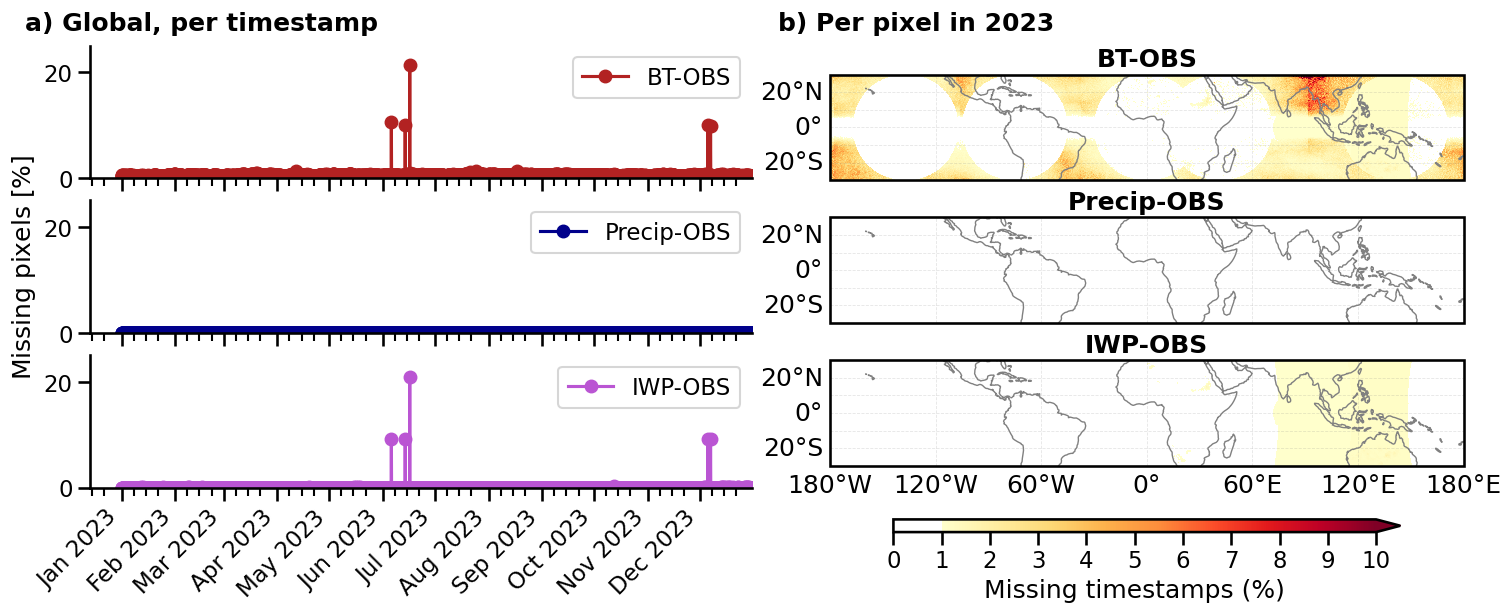

In [10]:
sns.set_context("talk")
vmax = 10

# fig set up
fig = plt.figure(figsize=(15, 6), constrained_layout=True)

gs = GridSpec(2, 2, figure=fig, height_ratios=[0.05, 1], width_ratios=[1, 1])

ax_col1_title = fig.add_subplot(gs[0, 0])
ax_col2_title = fig.add_subplot(gs[0, 1])

totaltimestamps = gettotaltimestampsfrompreciptcount(data)

for ax, title in zip([ax_col1_title, ax_col2_title], ["a) Global, per timestamp", f"b) Per pixel in 2023"]):
    ax.text(0.02, 0.5, title, ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.axis('off')


ax_ts =  gs[1, 0].subgridspec(3, 1, hspace=0.0)
ax_ts1 = fig.add_subplot(ax_ts[0])
ax_ts2 = fig.add_subplot(ax_ts[1], sharex=ax_ts1)
ax_ts3 = fig.add_subplot(ax_ts[2], sharex=ax_ts1)

gs_right = gs[1, 1].subgridspec(3, 1, hspace=0.0)
ax_map1 = fig.add_subplot(gs_right[0], projection=ccrs.PlateCarree())
ax_map2 = fig.add_subplot(gs_right[1], projection=ccrs.PlateCarree())
ax_map3 = fig.add_subplot(gs_right[2], projection=ccrs.PlateCarree())


# 3 maps
fig, ax_map1, _ = domain_plot_missing( result["tb_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="BT-OBS",bottom_grid_label = False, fig=fig, ax=ax_map1)
fig, ax_map2, _ = domain_plot_missing( result["precip_map"]["nan"], totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="Precip-OBS",bottom_grid_label= False, fig=fig, ax=ax_map2)
fig, ax_map3, _ = domain_plot_missing( result["iwp_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="IWP-OBS",bottom_grid_label= True, fig=fig, ax=ax_map3)

# coorba rmaps
# sm = plt.cm.ScalarMappable( cmap="Reds", norm=plt.Normalize(vmin=1, vmax=vmax))
# cbar = fig.colorbar( sm, ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
# cbar.set_label("Missing pixels (%)")

pcm = ax_map1.collections[0]
sm = plt.cm.ScalarMappable(cmap=pcm.cmap, norm=plt.Normalize(vmin=1, vmax=vmax))

cbar = fig.colorbar(sm,  ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
cbar.set_ticks(range(0, vmax + 1, max(1, vmax // 10)))
cbar.set_label("Missing timestamps (%)")

     
# timeseries
totalpixels = result["precip_map"]["nan"].size

ax_ts1.plot( result["tb_count"].time, 100 * result["tb_count"]["nan"] / totalpixels, label="BT-OBS", color=color_tb_obs, marker='o', zorder=1)
ax_ts2.plot( result["precip_count"].time, 100 * result["precip_count"]["nan"] / totalpixels, label="Precip-OBS", color=color_precip_obs, marker='o')
ax_ts3.plot( result["iwp_count"].time, 100 * result["iwp_count"]["nan"] / totalpixels, label="IWP-OBS", color=color_iwp_obs, marker='o', zorder=0)


# formatting — apply to each axes individually
for ax in [ax_ts1, ax_ts2, ax_ts3]:
    ax.set_ylim(0, 25)
    ax.legend(frameon=True)
    sns.despine(ax=ax)

ax_ts2.set_ylabel("Missing pixels [$\\%$]")

# one day
# ax_ts.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
# ax_ts.xaxis.set_major_locator(mdates.DayLocator())
# ax_ts.xaxis.set_minor_locator( mdates.HourLocator(byhour=range(0, 24, 3)))

# # one month
# ax_ts3.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
# ax_ts3.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
# ax_ts3.xaxis.set_minor_locator(mdates.DayLocator())


# year
ax_ts3.xaxis.set_major_formatter(DateFormatter("%b %Y"))
ax_ts3.xaxis.set_major_locator(mdates.MonthLocator())
ax_ts3.xaxis.set_minor_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
ax_ts3.set_xlim(right=pd.Timestamp("2023-12-31"))


plt.setp(ax_ts3.get_xticklabels(), rotation=45, ha='right')

# hide x tick labels on upper two
for ax in [ax_ts1, ax_ts2]:
    plt.setp(ax.get_xticklabels(), visible=False)

#fig.suptitle(f"{date_label_map}", fontweight = "bold")

#plt.savefig(os.path.join(plotsavedir,"missingpixels_combiplot_ts_maps.pdf"),bbox_inches="tight")
plt.show()


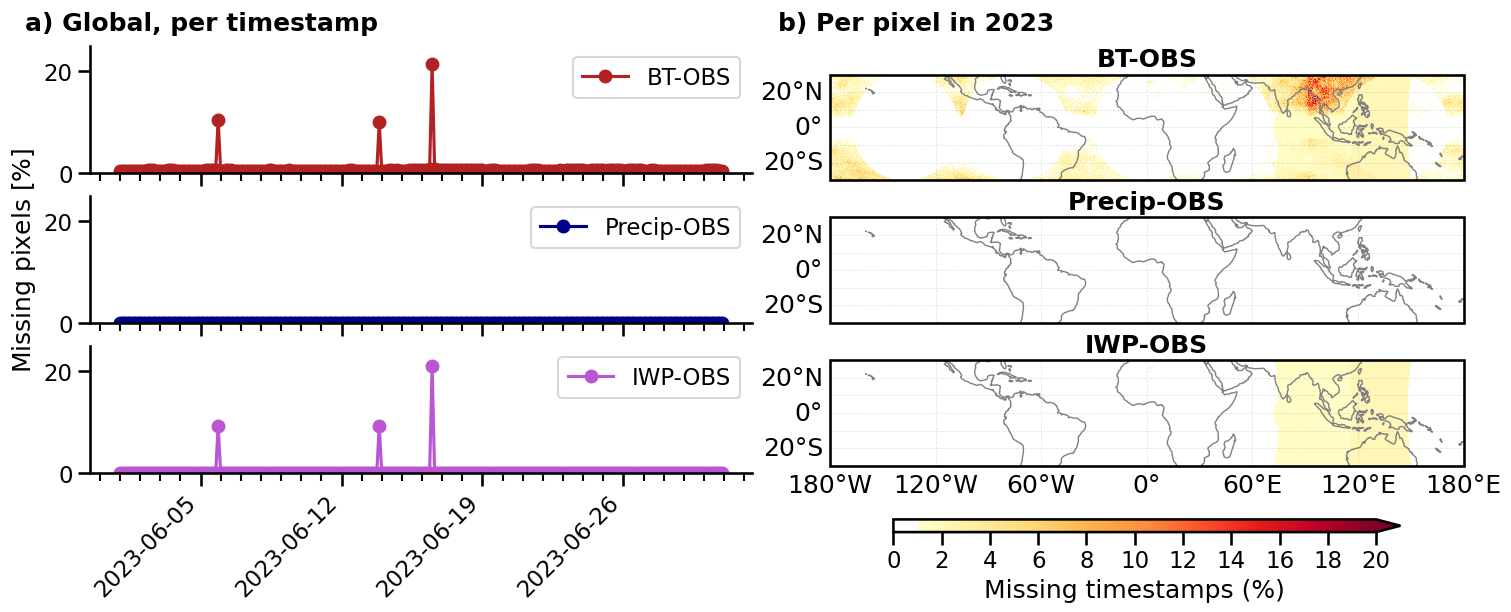

In [11]:
sns.set_context("talk")

vmax = 20

# fig set up
fig = plt.figure(figsize=(15, 6), constrained_layout=True)

gs = GridSpec(2, 2, figure=fig, height_ratios=[0.05, 1], width_ratios=[1, 1])

ax_col1_title = fig.add_subplot(gs[0, 0])
ax_col2_title = fig.add_subplot(gs[0, 1])

# b) 
totaltimestamps = 30*8#  gettotaltimestampsfrompreciptcount(data) only works for whole dataset
# a) timeseries
totalpixels = result_june["precip_map"]["nan"].size

for ax, title in zip([ax_col1_title, ax_col2_title], [f"a) Global, per timestamp", f"b) Per pixel in 2023"]):
    ax.text(0.02, 0.5, title, ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.axis('off')


ax_ts =  gs[1, 0].subgridspec(3, 1, hspace=0.0)
ax_ts1 = fig.add_subplot(ax_ts[0])
ax_ts2 = fig.add_subplot(ax_ts[1], sharex=ax_ts1)
ax_ts3 = fig.add_subplot(ax_ts[2], sharex=ax_ts1)

gs_right = gs[1, 1].subgridspec(3, 1, hspace=0.0)
ax_map1 = fig.add_subplot(gs_right[0], projection=ccrs.PlateCarree())
ax_map2 = fig.add_subplot(gs_right[1], projection=ccrs.PlateCarree())
ax_map3 = fig.add_subplot(gs_right[2], projection=ccrs.PlateCarree())


# 3 maps
fig, ax_map1, _ = domain_plot_missing( result_june["tb_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="BT-OBS",bottom_grid_label = False, fig=fig, ax=ax_map1)
fig, ax_map2, _ = domain_plot_missing( result_june["precip_map"]["nan"], totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="Precip-OBS",bottom_grid_label= False, fig=fig, ax=ax_map2)
fig, ax_map3, _ = domain_plot_missing( result_june["iwp_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="IWP-OBS",bottom_grid_label= True, fig=fig, ax=ax_map3)

# coorba rmaps
# sm = plt.cm.ScalarMappable( cmap="Reds", norm=plt.Normalize(vmin=1, vmax=vmax))
# cbar = fig.colorbar( sm, ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
# cbar.set_label("Missing pixels (%)")

pcm = ax_map1.collections[0]
sm = plt.cm.ScalarMappable(cmap=pcm.cmap, norm=plt.Normalize(vmin=1, vmax=vmax))

cbar = fig.colorbar(sm,  ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
cbar.set_ticks(range(0, vmax + 1, max(1, vmax // 10)))
cbar.set_label("Missing timestamps (%)")

     


ax_ts1.plot( result_june["tb_count"].time, 100 * result_june["tb_count"]["nan"] / totalpixels, label="BT-OBS", color=color_tb_obs, marker='o', zorder=1)
ax_ts2.plot( result_june["precip_count"].time, 100 * result_june["precip_count"]["nan"] / totalpixels, label="Precip-OBS", color=color_precip_obs, marker='o')
ax_ts3.plot( result_june["iwp_count"].time, 100 * result_june["iwp_count"]["nan"] / totalpixels, label="IWP-OBS", color=color_iwp_obs, marker='o', zorder=0)


# formatting — apply to each axes individually
for ax in [ax_ts1, ax_ts2, ax_ts3]:
    ax.set_ylim(0, 25)
    ax.legend(frameon=True)
    sns.despine(ax=ax)

ax_ts2.set_ylabel("Missing pixels [$\\%$]")


# one month
ax_ts3.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
ax_ts3.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax_ts3.xaxis.set_minor_locator(mdates.DayLocator())


# # year
# ax_ts3.xaxis.set_major_formatter(DateFormatter("%b %Y"))
# ax_ts3.xaxis.set_major_locator(mdates.MonthLocator())
# ax_ts3.xaxis.set_minor_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
# ax_ts3.set_xlim(right=pd.Timestamp("2023-12-31"))


plt.setp(ax_ts3.get_xticklabels(), rotation=45, ha='right')

# hide x tick labels on upper two
for ax in [ax_ts1, ax_ts2]:
    plt.setp(ax.get_xticklabels(), visible=False)

#fig.suptitle(f"{date_label_map_june}", fontweight = "bold")

#plt.savefig(os.path.join(plotsavedir,"missingpixels_combiplot_ts_maps.pdf"),bbox_inches="tight")
plt.show()


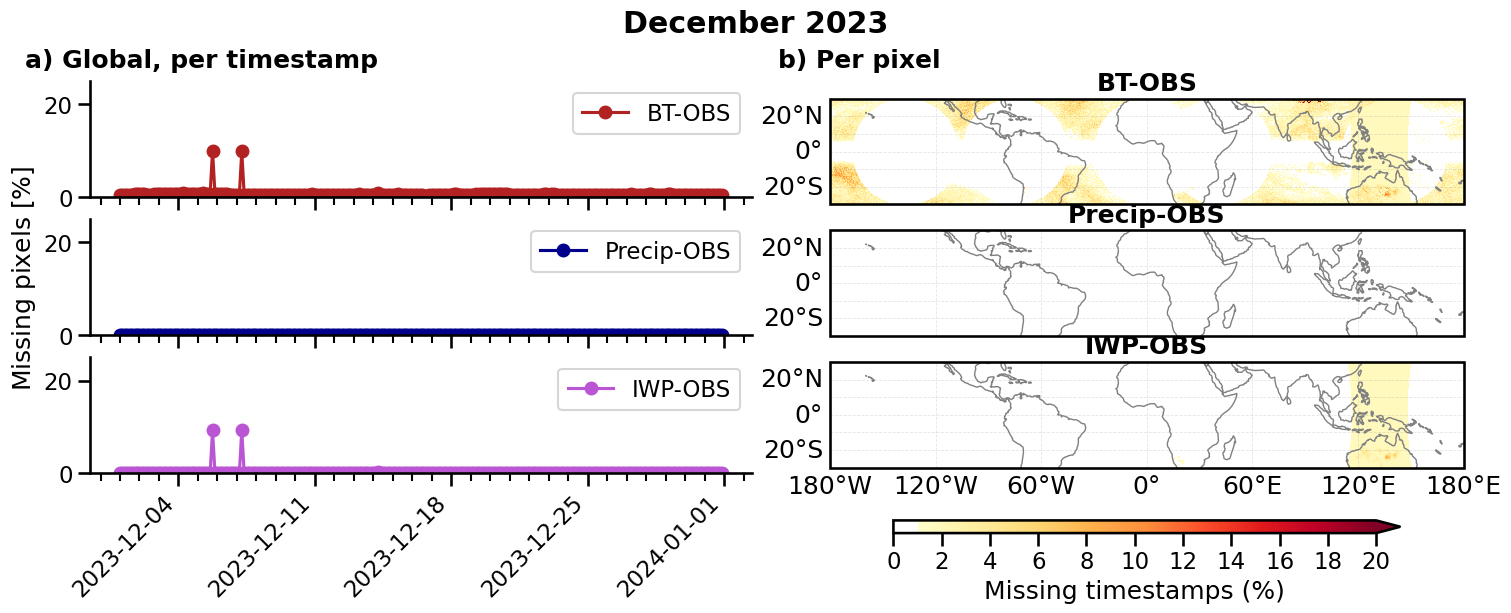

In [12]:
sns.set_context("talk")

vmax = 20

# fig set up
fig = plt.figure(figsize=(15, 6), constrained_layout=True)

gs = GridSpec(2, 2, figure=fig, height_ratios=[0.05, 1], width_ratios=[1, 1])

ax_col1_title = fig.add_subplot(gs[0, 0])
ax_col2_title = fig.add_subplot(gs[0, 1])

# b) 
totaltimestamps = 31*8#  gettotaltimestampsfrompreciptcount(data) only works for whole dataset
# a) timeseries
totalpixels = result_december["precip_map"]["nan"].size

for ax, title in zip([ax_col1_title, ax_col2_title], [f"a) Global, per timestamp", f"b) Per pixel"]):
    ax.text(0.02, 0.5, title, ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.axis('off')


ax_ts =  gs[1, 0].subgridspec(3, 1, hspace=0.0)
ax_ts1 = fig.add_subplot(ax_ts[0])
ax_ts2 = fig.add_subplot(ax_ts[1], sharex=ax_ts1)
ax_ts3 = fig.add_subplot(ax_ts[2], sharex=ax_ts1)

gs_right = gs[1, 1].subgridspec(3, 1, hspace=0.0)
ax_map1 = fig.add_subplot(gs_right[0], projection=ccrs.PlateCarree())
ax_map2 = fig.add_subplot(gs_right[1], projection=ccrs.PlateCarree())
ax_map3 = fig.add_subplot(gs_right[2], projection=ccrs.PlateCarree())


# 3 maps
fig, ax_map1, _ = domain_plot_missing( result_december["tb_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="BT-OBS",bottom_grid_label = False, fig=fig, ax=ax_map1)
fig, ax_map2, _ = domain_plot_missing( result_december["precip_map"]["nan"], totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="Precip-OBS",bottom_grid_label= False, fig=fig, ax=ax_map2)
fig, ax_map3, _ = domain_plot_missing( result_december["iwp_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="IWP-OBS",bottom_grid_label= True, fig=fig, ax=ax_map3)

# coorba rmaps
# sm = plt.cm.ScalarMappable( cmap="Reds", norm=plt.Normalize(vmin=1, vmax=vmax))
# cbar = fig.colorbar( sm, ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
# cbar.set_label("Missing pixels (%)")

pcm = ax_map1.collections[0]
sm = plt.cm.ScalarMappable(cmap=pcm.cmap, norm=plt.Normalize(vmin=1, vmax=vmax))

cbar = fig.colorbar(sm,  ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
cbar.set_ticks(range(0, vmax + 1, max(1, vmax // 10)))
cbar.set_label("Missing timestamps (%)")

     


ax_ts1.plot( result_december["tb_count"].time, 100 * result_december["tb_count"]["nan"] / totalpixels, label="BT-OBS", color=color_tb_obs, marker='o', zorder=1)
ax_ts2.plot( result_december["precip_count"].time, 100 * result_december["precip_count"]["nan"] / totalpixels, label="Precip-OBS", color=color_precip_obs, marker='o')
ax_ts3.plot( result_december["iwp_count"].time, 100 * result_december["iwp_count"]["nan"] / totalpixels, label="IWP-OBS", color=color_iwp_obs, marker='o', zorder=0)


# formatting — apply to each axes individually
for ax in [ax_ts1, ax_ts2, ax_ts3]:
    ax.set_ylim(0, 25)
    ax.legend(frameon=True)
    sns.despine(ax=ax)

ax_ts2.set_ylabel("Missing pixels [$\\%$]")


# one month
ax_ts3.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
ax_ts3.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
ax_ts3.xaxis.set_minor_locator(mdates.DayLocator())




plt.setp(ax_ts3.get_xticklabels(), rotation=45, ha='right')

# hide x tick labels on upper two
for ax in [ax_ts1, ax_ts2]:
    plt.setp(ax.get_xticklabels(), visible=False)

fig.suptitle(f"{date_label_map_december}", fontweight = "bold")

#plt.savefig(os.path.join(plotsavedir,"missingpixels_combiplot_ts_maps.pdf"),bbox_inches="tight")
plt.show()


In [13]:
#a) timeseries
ds = result
totalpixels = ds["tb_map"]["nan"].size

pct = 100 * ds["tb_count"]["nan"] / totalpixels   # DataArray with time dim

zero_ts = (ds["tb_count"]["nan"].values == 0).sum()  # check raw counts, not pct
print(f"Timestamps with 0 missing pixels: {zero_ts:,} ({100*zero_ts/len(pct.values):.1f}%)")

# below background 
below = pct < 1.3

vals, counts = np.unique(below,return_counts = True) 
for v, c in zip(vals, counts):
    label = "Timestamps with <1.3% missing pixels" if v else " Timestamps with ≥1.3% missing pixels"
    print(f"{label}: {c:,} timestamps ({100*c/counts.sum():.1f}%)")

# get timestamps of 5 highest values
print("\nTimestamps of highest values:")
top5_idx = np.argsort(pct.values)[-10:][::-1]
for i in top5_idx:
    print(f"  {pd.Timestamp(pct.time.values[i])}  →  {pct.values[i]:.2f}% missing")

#################################


Timestamps with 0 missing pixels: 0 (0.0%)
 Timestamps with ≥1.3% missing pixels: 5 timestamps (0.2%)
Timestamps with <1.3% missing pixels: 2,915 timestamps (99.8%)

Timestamps of highest values:
  2023-06-16 12:00:00  →  21.41% missing
  2023-06-05 21:00:00  →  10.51% missing
  2023-06-13 21:00:00  →  9.97% missing
  2023-12-05 18:00:00  →  9.97% missing
  2023-12-07 06:00:00  →  9.84% missing
  2023-04-11 21:00:00  →  1.27% missing
  2023-08-17 09:00:00  →  1.27% missing
  2023-07-24 21:00:00  →  1.27% missing
  2023-07-21 09:00:00  →  1.07% missing
  2023-07-21 06:00:00  →  0.93% missing


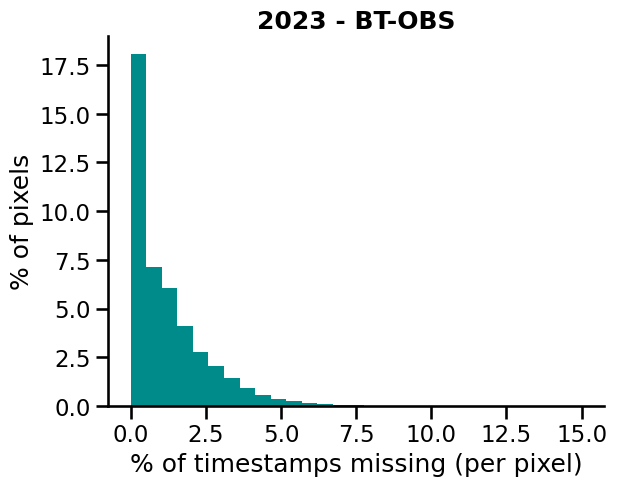

In [14]:
# b)
ds = result
totalpixels = ds["tb_map"]["nan"].size
totaltimestamps = gettotaltimestampsfrompreciptcount(data)# only works for whole dataset

missing = 100 * ds["tb_map"] / totaltimestamps
missing = missing["nan"].values.flatten()
missing = missing[(missing > 0) & (~np.isnan(missing))]


weights = np.ones_like(missing) / totalpixels * 100
plt.hist(missing, bins=np.linspace(0, 15, 30), weights=weights,color="darkcyan")
plt.xlabel("% of timestamps missing (per pixel)")
plt.ylabel("% of pixels")
plt.title("2023 - BT-OBS", fontweight= "bold")
sns.despine()

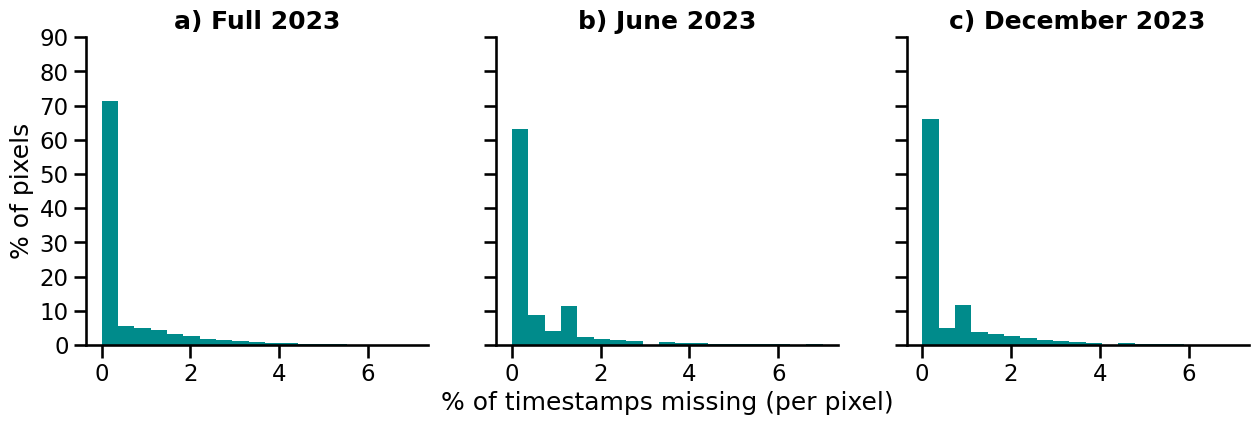

In [15]:
#b) timeseries
totalpixels = ds["tb_map"]["nan"].size

def get_missing_and_weights(ds,totalpixels,totaltimestamps):
    missing = 100 * ds["tb_map"] / totaltimestamps
    missing = missing["nan"].values.flatten()
    count0s = 100* len(missing[(missing == 0)])/totalpixels
    #missing= missing[(missing > 0)]
    weights = np.ones_like(missing) / totalpixels * 100
    return missing, weights, count0s

missing_dec, weights_dec , count0s_dec= get_missing_and_weights(ds = result_december,totalpixels = totalpixels,totaltimestamps = 31*8)
missing_jun, weights_jun,count0s_jun= get_missing_and_weights(ds = result_june,totalpixels = totalpixels,totaltimestamps = 30*8)
missing, weights,count0s= get_missing_and_weights(ds = result,totalpixels = totalpixels,totaltimestamps = gettotaltimestampsfrompreciptcount(data))


fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

ax[0].hist(missing, bins=np.linspace(0, 7, 20), weights=weights,color="darkcyan")
#ax[0].set_xlabel("% of timestamps missing (per pixel)")
ax[0].set_ylabel("% of pixels")
ax[0].set_title("a) Full 2023", fontweight= "bold")


ax[1].hist(missing_jun, bins=np.linspace(0, 7, 20), weights=weights_jun,color="darkcyan")
ax[1].set_xlabel("% of timestamps missing (per pixel)")
#ax[1].set_ylabel("% of pixels")
ax[1].set_title("b) June 2023", fontweight= "bold")

ax[2].hist(missing_dec, bins=np.linspace(0, 7, 20), weights=weights_dec,color="darkcyan")
#ax[2].set_xlabel("% of timestamps missing (per pixel)")
#ax[2].set_ylabel("% of pixels")
ax[2].set_title("c) December 2023", fontweight= "bold")

plt.ylim(0,90)
plt.yticks(range(0, 91, 10))
sns.despine()

#plt.savefig(os.path.join(plotsavedir,"missingpixels_histogramms.pdf"),bbox_inches="tight")
plt.show()

# cut the days with missing and plots again

In [17]:
drop_dates = [
    "2023-06-16", "2023-06-05", "2023-06-13",
    "2023-12-05", "2023-12-07"
]

date_suffixes_clean = [d for d in date_suffixes 
                       if not any(d.startswith(drop) for drop in drop_dates)]
#date_suffixes_clean

data_clean = {name: [] for name in name_types}

for date_suffix in date_suffixes_clean:
    for name, key in zip(name_types, file_keys):
        data_clean[name].append(xr.open_dataset(os.path.join(input_dir, f"{key}_{date_suffix}.nc"), engine="h5netcdf"))

# summarize (in one cell bc of annoying output)
date_label_map = "2023"
result_clean, label = summarize_period(data_clean, date_suffixes_clean)

date_label_map_june = "June 2023"
result_clean_june, label_june = summarize_period(data_clean, date_suffixes_clean, month = 6)

date_label_map_december = "December 2023"
result_clean_december, label_december= summarize_period(data_clean, date_suffixes_clean, month = 12)



/tmp/ipykernel_680824/1293946388.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


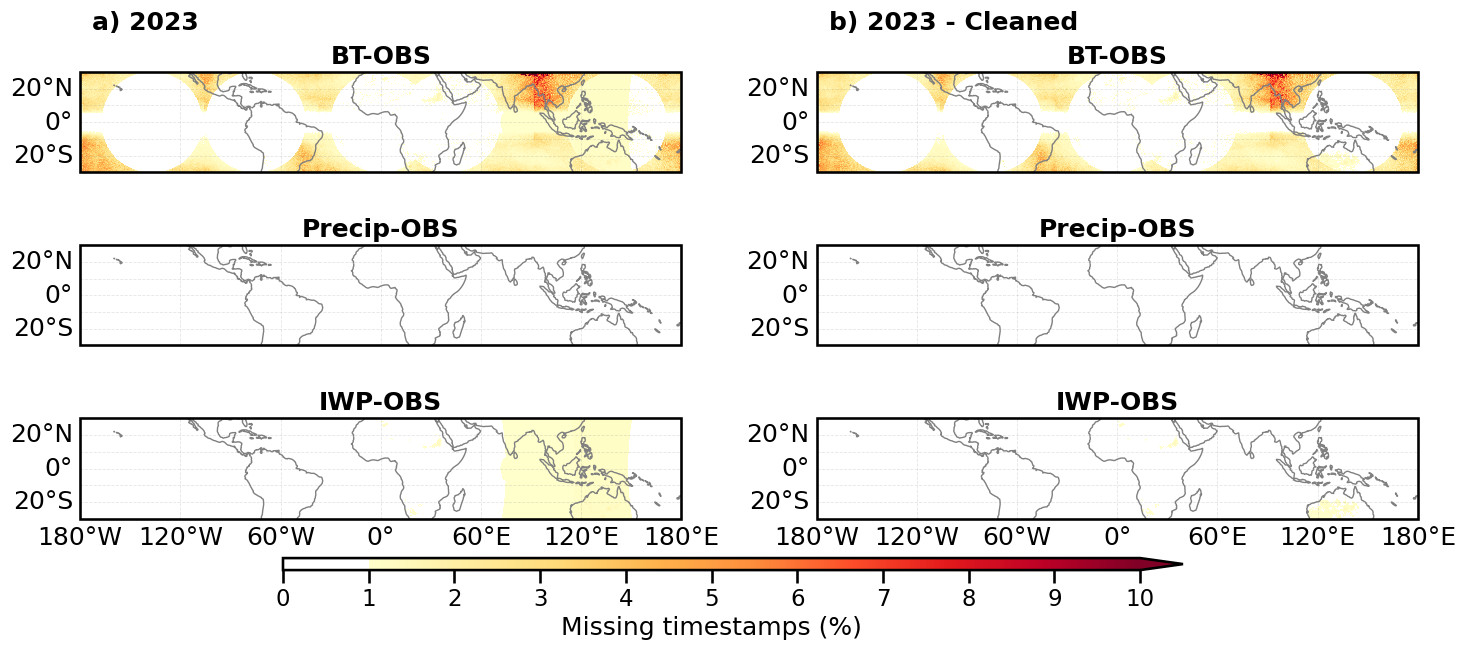

In [21]:
sns.set_context("talk")
vmax = 10
# fig set up
fig = plt.figure(figsize=(15, 6), constrained_layout=False)
gs = GridSpec(2, 2, figure=fig, height_ratios=[0.05, 1], width_ratios=[1, 1],hspace = 0.0)
ax_col1_title = fig.add_subplot(gs[0, 0])
ax_col2_title = fig.add_subplot(gs[0, 1])
totaltimestamps = gettotaltimestampsfrompreciptcount(data)
for ax, title in zip([ax_col1_title, ax_col2_title], ["a) 2023", "b) 2023 - Cleaned"]):
    ax.text(0.02, 0.5, title, ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.axis('off')
# left: result
gs_left = gs[1, 0].subgridspec(3, 1, hspace=0.0)
ax_map1 = fig.add_subplot(gs_left[0], projection=ccrs.PlateCarree())
ax_map2 = fig.add_subplot(gs_left[1], projection=ccrs.PlateCarree())
ax_map3 = fig.add_subplot(gs_left[2], projection=ccrs.PlateCarree())
# right: result_clean
gs_right = gs[1, 1].subgridspec(3, 1, hspace=0.0)
ax_map1c = fig.add_subplot(gs_right[0], projection=ccrs.PlateCarree())
ax_map2c = fig.add_subplot(gs_right[1], projection=ccrs.PlateCarree())
ax_map3c = fig.add_subplot(gs_right[2], projection=ccrs.PlateCarree())
# 3 maps — result (left)
fig, ax_map1, _ = domain_plot_missing(result["tb_map"]["nan"],     totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="BT-OBS",     bottom_grid_label=False, fig=fig, ax=ax_map1)
fig, ax_map2, _ = domain_plot_missing(result["precip_map"]["nan"], totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="Precip-OBS", bottom_grid_label=False, fig=fig, ax=ax_map2)
fig, ax_map3, _ = domain_plot_missing(result["iwp_map"]["nan"],    totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="IWP-OBS",    bottom_grid_label=True,  fig=fig, ax=ax_map3)
# 3 maps — result_clean (right)
totaltimestamps_clean = gettotaltimestampsfrompreciptcount(data_clean)
fig, ax_map1c, _ = domain_plot_missing(result_clean["tb_map"]["nan"],     totaltimestamps=totaltimestamps_clean, vmax=vmax, domain=[-180, 180, -30, 30], title="BT-OBS",     bottom_grid_label=False, fig=fig, ax=ax_map1c)
fig, ax_map2c, _ = domain_plot_missing(result_clean["precip_map"]["nan"], totaltimestamps=totaltimestamps_clean, vmax=vmax, domain=[-180, 180, -30, 30], title="Precip-OBS", bottom_grid_label=False, fig=fig, ax=ax_map2c)
fig, ax_map3c, _ = domain_plot_missing(result_clean["iwp_map"]["nan"],    totaltimestamps=totaltimestamps_clean, vmax=vmax, domain=[-180, 180, -30, 30], title="IWP-OBS",    bottom_grid_label=True,  fig=fig, ax=ax_map3c)

# after plt.show() remove, before plt.savefig, add:
fig.subplots_adjust(bottom=0.08)  # add after all plots, before colorbar
cbar_ax = fig.add_axes([0.2, 0.02, 0.6, 0.02])
pcm = ax_map1.collections[0]
sm = plt.cm.ScalarMappable(cmap=pcm.cmap, norm=plt.Normalize(vmin=1, vmax=vmax))
cbar = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal", extend="max")
cbar.set_ticks(range(0, vmax + 1, max(1, vmax // 10)))
cbar.set_label("Missing timestamps (%)")


plt.tight_layout()
plt.savefig(os.path.join(plotsavedir, "missingpixels_before_after_clean.pdf"), bbox_inches="tight")
plt.show()

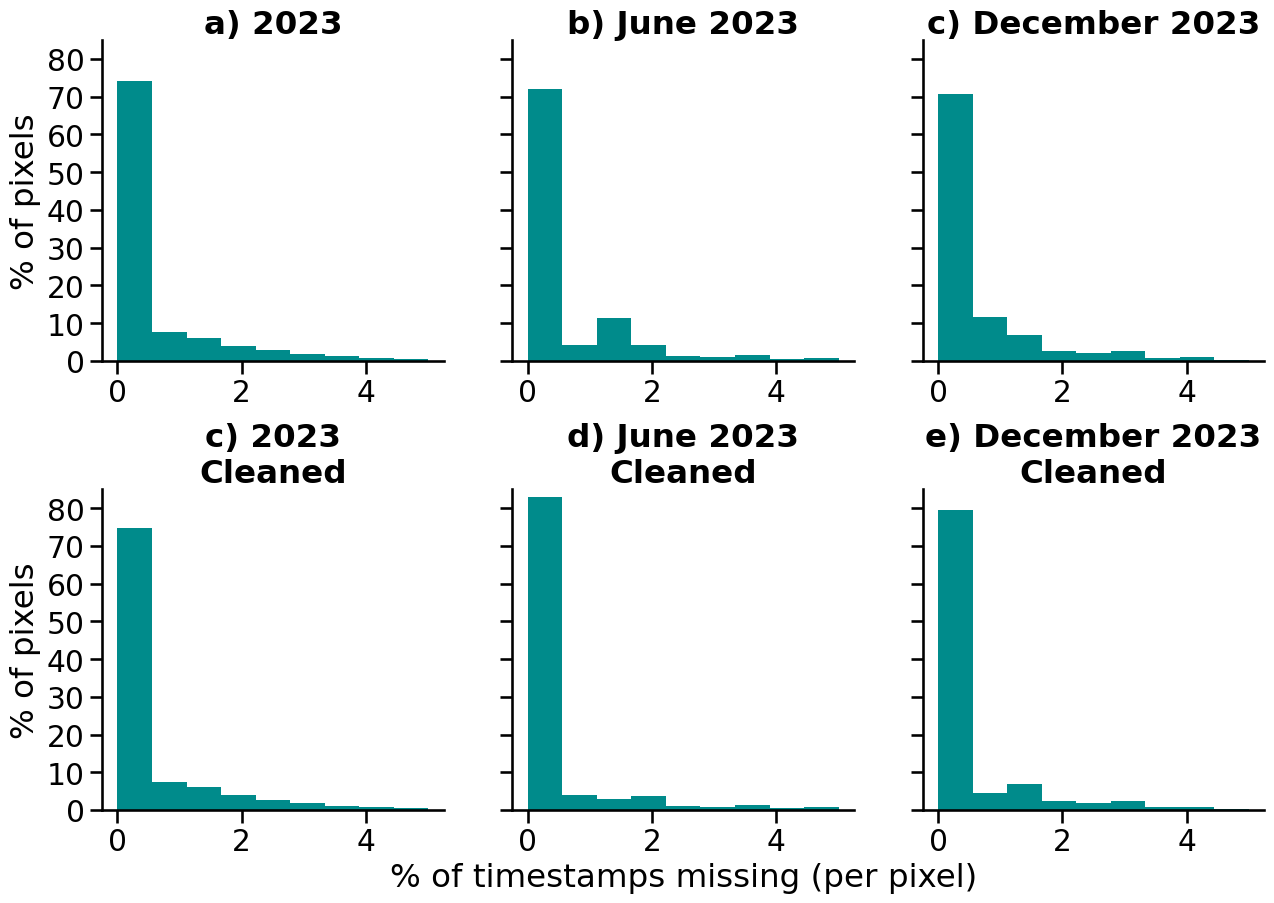

In [41]:
#b) timeseries
totalpixels = ds["tb_map"]["nan"].size

def get_missing_and_weights(ds,totalpixels,totaltimestamps):
    missing = 100 * ds["tb_map"] / totaltimestamps
    missing = missing["nan"].values.flatten()
    count0s = 100* len(missing[(missing == 0)])/totalpixels
    #missing= missing[(missing > 0)]
    weights = np.ones_like(missing) / totalpixels * 100
    return missing, weights, count0s

missing_dec_clean, weights_dec_clean, count0s_dec_clean= get_missing_and_weights(ds = result_clean_december,totalpixels = totalpixels,totaltimestamps = 31*8)
missing_jun_clean, weights_jun_clean,count0s_jun_clean= get_missing_and_weights(ds = result_clean_june,totalpixels = totalpixels,totaltimestamps = 30*8)
missing_clean, weights_clean,count0s_clean= get_missing_and_weights(ds = result_clean,totalpixels = totalpixels,totaltimestamps = gettotaltimestampsfrompreciptcount(data))

sns.set_context("talk", font_scale = 1.3)

fig, ax = plt.subplots(2, 3, figsize=(15,10 ), sharey=True)
plt.rcParams["axes.titlepad"] = 1

ax[0,0].hist(missing, bins=np.linspace(0, 5, 10), weights=weights,color="darkcyan")
ax[0,0].set_ylabel("% of pixels")
ax[0,0].set_title("a) 2023", fontweight= "bold")


ax[0,1].hist(missing_jun, bins=np.linspace(0, 5, 10), weights=weights_jun,color="darkcyan")
#ax[0,1].set_xlabel("% of timestamps missing (per pixel)")
ax[0,1].set_title("b) June 2023", fontweight= "bold")

ax[0,2].hist(missing_dec, bins=np.linspace(0, 5, 10), weights=weights_dec,color="darkcyan")
ax[0,2].set_title("c) December 2023", fontweight= "bold")

# clean
ax[1,0].hist(missing_clean, bins=np.linspace(0, 5, 10), weights=weights_clean,color="darkcyan")
ax[1,0].set_ylabel("% of pixels")
ax[1,0].set_title("c) 2023\nCleaned", fontweight= "bold")


ax[1,1].hist(missing_jun_clean, bins=np.linspace(0, 5, 10), weights=weights_jun_clean,color="darkcyan")
ax[1,1].set_xlabel("% of timestamps missing (per pixel)")
ax[1,1].set_title("d) June 2023\nCleaned", fontweight= "bold")

ax[1,2].hist(missing_dec_clean, bins=np.linspace(0, 5, 10), weights=weights_dec_clean,color="darkcyan")
ax[1,2].set_title("e) December 2023\nCleaned", fontweight= "bold")



plt.ylim(0,85)
plt.yticks(range(0, 81, 10))
sns.despine()

fig.subplots_adjust(hspace=0.4)   # increase until the rows no longer touch

plt.savefig(os.path.join(plotsavedir,"missingpixels_histogramms_before_and_after_clean.pdf"),bbox_inches="tight")
plt.show()

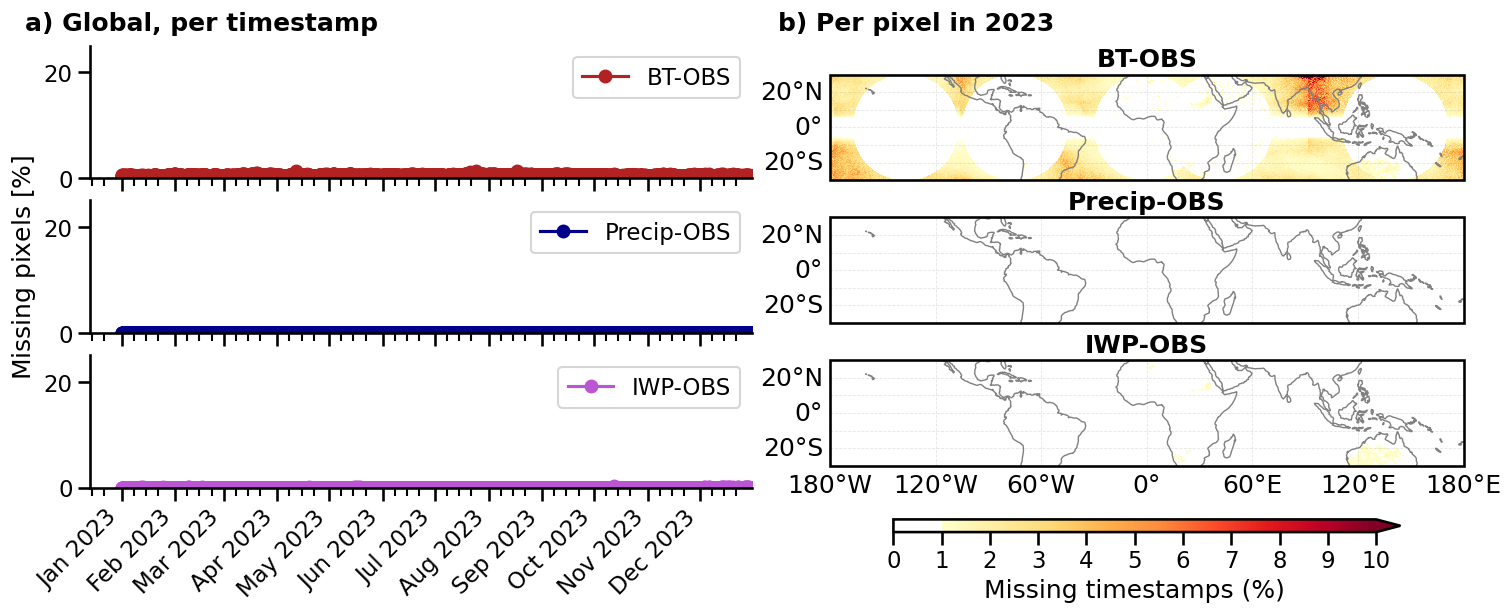

In [20]:
import pandas as pd
sns.set_context("talk")
vmax = 10

# fig set up
fig = plt.figure(figsize=(15, 6), constrained_layout=True)

gs = GridSpec(2, 2, figure=fig, height_ratios=[0.05, 1], width_ratios=[1, 1])

ax_col1_title = fig.add_subplot(gs[0, 0])
ax_col2_title = fig.add_subplot(gs[0, 1])

totaltimestamps = gettotaltimestampsfrompreciptcount(data)

for ax, title in zip([ax_col1_title, ax_col2_title], ["a) Global, per timestamp", f"b) Per pixel in 2023"]):
    ax.text(0.02, 0.5, title, ha='left', va='center', fontweight='bold', transform=ax.transAxes)
    ax.axis('off')


ax_ts =  gs[1, 0].subgridspec(3, 1, hspace=0.0)
ax_ts1 = fig.add_subplot(ax_ts[0])
ax_ts2 = fig.add_subplot(ax_ts[1], sharex=ax_ts1)
ax_ts3 = fig.add_subplot(ax_ts[2], sharex=ax_ts1)

gs_right = gs[1, 1].subgridspec(3, 1, hspace=0.0)
ax_map1 = fig.add_subplot(gs_right[0], projection=ccrs.PlateCarree())
ax_map2 = fig.add_subplot(gs_right[1], projection=ccrs.PlateCarree())
ax_map3 = fig.add_subplot(gs_right[2], projection=ccrs.PlateCarree())


# 3 maps
fig, ax_map1, _ = domain_plot_missing( result_clean["tb_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="BT-OBS",bottom_grid_label = False, fig=fig, ax=ax_map1)
fig, ax_map2, _ = domain_plot_missing( result_clean["precip_map"]["nan"], totaltimestamps=totaltimestamps, vmax=vmax, domain=[-180, 180, -30, 30], title="Precip-OBS",bottom_grid_label= False, fig=fig, ax=ax_map2)
fig, ax_map3, _ = domain_plot_missing( result_clean["iwp_map"]["nan"],totaltimestamps=totaltimestamps,  vmax=vmax, domain=[-180, 180, -30, 30], title="IWP-OBS",bottom_grid_label= True, fig=fig, ax=ax_map3)

# coorba rmaps
# sm = plt.cm.ScalarMappable( cmap="Reds", norm=plt.Normalize(vmin=1, vmax=vmax))
# cbar = fig.colorbar( sm, ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
# cbar.set_label("Missing pixels (%)")

pcm = ax_map1.collections[0]
sm = plt.cm.ScalarMappable(cmap=pcm.cmap, norm=plt.Normalize(vmin=1, vmax=vmax))

cbar = fig.colorbar(sm,  ax=[ax_map1, ax_map2, ax_map3], orientation="horizontal", pad=0.05, shrink=0.8, aspect=40, extend="max")
cbar.set_ticks(range(0, vmax + 1, max(1, vmax // 10)))
cbar.set_label("Missing timestamps (%)")

     
# timeseries
totalpixels = result_clean["precip_map"]["nan"].size

ax_ts1.plot( result_clean["tb_count"].time, 100 * result_clean["tb_count"]["nan"] / totalpixels, label="BT-OBS", color=color_tb_obs, marker='o', zorder=1)
ax_ts2.plot( result_clean["precip_count"].time, 100 * result_clean["precip_count"]["nan"] / totalpixels, label="Precip-OBS", color=color_precip_obs, marker='o')
ax_ts3.plot( result_clean["iwp_count"].time, 100 * result_clean["iwp_count"]["nan"] / totalpixels, label="IWP-OBS", color=color_iwp_obs, marker='o', zorder=0)


# formatting — apply to each axes individually
for ax in [ax_ts1, ax_ts2, ax_ts3]:
    ax.set_ylim(0, 25)
    ax.legend(frameon=True)
    sns.despine(ax=ax)

ax_ts2.set_ylabel("Missing pixels [$\\%$]")

# one day
# ax_ts.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
# ax_ts.xaxis.set_major_locator(mdates.DayLocator())
# ax_ts.xaxis.set_minor_locator( mdates.HourLocator(byhour=range(0, 24, 3)))

# # one month
# ax_ts3.xaxis.set_major_formatter(DateFormatter("%Y-%m-%d"))
# ax_ts3.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO))
# ax_ts3.xaxis.set_minor_locator(mdates.DayLocator())


# year
ax_ts3.xaxis.set_major_formatter(DateFormatter("%b %Y"))
ax_ts3.xaxis.set_major_locator(mdates.MonthLocator())
ax_ts3.xaxis.set_minor_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
ax_ts3.set_xlim(right=pd.Timestamp("2023-12-31"))


plt.setp(ax_ts3.get_xticklabels(), rotation=45, ha='right')

# hide x tick labels on upper two
for ax in [ax_ts1, ax_ts2]:
    plt.setp(ax.get_xticklabels(), visible=False)

#fig.suptitle(f"{date_label_map}", fontweight = "bold")

#plt.savefig(os.path.join(plotsavedir,"missingpixels_combiplot_ts_maps.pdf"),bbox_inches="tight")
plt.show()
